In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dossier contenant les données nettoyées
DOSSIER = Path("../data/processed/date=2026-10-29")

# Dossier où enregistrer les graphiques
DOSSIER_FIGURES = Path("../reports/figures")
DOSSIER_FIGURES.mkdir(parents=True, exist_ok=True)

# Chargement des données
lignes = pd.read_csv(DOSSIER / "lignes_commande.csv")
commandes = pd.read_csv(DOSSIER / "commandes.csv")
clients = pd.read_csv(DOSSIER / "clients.csv")
produits = pd.read_csv(DOSSIER / "produits.csv")

# Préparer les dates
commandes["date_commande"] = pd.to_datetime(
    commandes["date_commande"],
    errors="coerce"
)

# Relier les lignes aux commandes
ventes = lignes.merge(
    commandes[["commande_id", "client_id", "date_commande"]],
    on="commande_id",
    how="left"
)

# Ajouter les informations géographiques
ventes = ventes.merge(
    clients[["client_id", "ville", "region"]],
    on="client_id",
    how="left"
)

# Ajouter les noms des produits
ventes_produits = lignes.merge(
    produits[["produit_id", "nom_produit", "categorie"]],
    on="produit_id",
    how="left"
)

# Style général des graphiques
sns.set_theme(style="whitegrid")

print("Données chargées.")
print("Lignes de commande :", len(lignes))
print("Commandes :", len(commandes))
print("Clients :", len(clients))
print("Produits :", len(produits))

Données chargées.
Lignes de commande : 9608
Commandes : 3920
Clients : 3333
Produits : 40


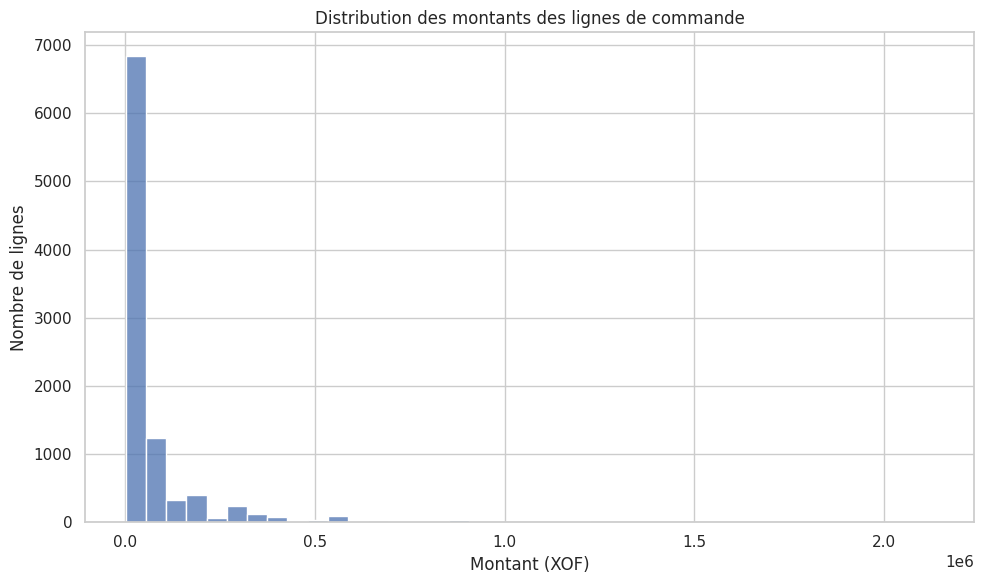

In [2]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=lignes,
    x="montant_xof",
    bins=40
)

plt.title("Distribution des montants des lignes de commande")
plt.xlabel("Montant (XOF)")
plt.ylabel("Nombre de lignes")

plt.tight_layout()
plt.savefig(
    DOSSIER_FIGURES / "01_distribution_montants.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()

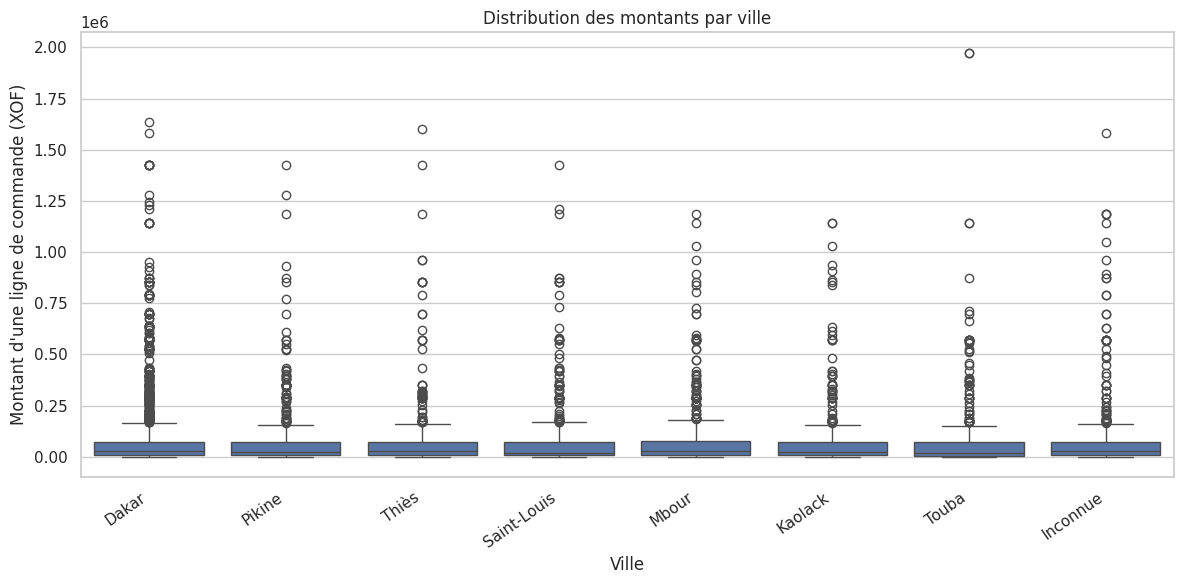

In [3]:
# Sélectionner les 8 villes les plus représentées en nombre de lignes
top_villes = (
    ventes["ville"]
    .fillna("Inconnue")
    .value_counts()
    .head(8)
    .index
)

ventes_boxplot = ventes.copy()
ventes_boxplot["ville"] = ventes_boxplot["ville"].fillna("Inconnue")

ventes_boxplot = ventes_boxplot[
    ventes_boxplot["ville"].isin(top_villes)
]

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=ventes_boxplot,
    x="ville",
    y="montant_xof"
)

plt.title("Distribution des montants par ville")
plt.xlabel("Ville")
plt.ylabel("Montant d'une ligne de commande (XOF)")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.savefig(
    DOSSIER_FIGURES / "02_montants_par_ville.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()

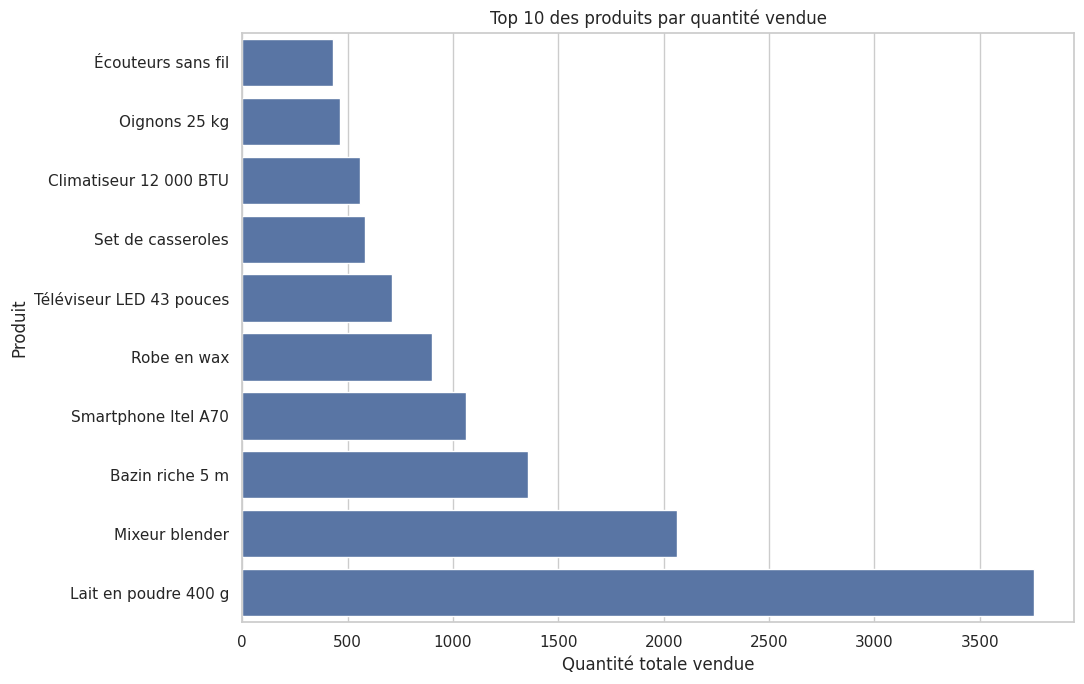

In [4]:
top10_quantite = (
    ventes_produits
    .groupby("nom_produit", as_index=False)
    .agg(quantite_totale=("quantite", "sum"))
    .sort_values("quantite_totale", ascending=False)
    .head(10)
    .sort_values("quantite_totale", ascending=True)
)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=top10_quantite,
    x="quantite_totale",
    y="nom_produit"
)

plt.title("Top 10 des produits par quantité vendue")
plt.xlabel("Quantité totale vendue")
plt.ylabel("Produit")

plt.tight_layout()
plt.savefig(
    DOSSIER_FIGURES / "03_top10_produits_quantite.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()


In [5]:
avis = pd.read_csv(DOSSIER / "avis.csv")

In [6]:
# Nombre de commandes par client
nb_commandes = (
    commandes.groupby("client_id")
    .agg(nb_commandes=("commande_id", "nunique"))
)

# Chiffre d'affaires total par client
ca_clients = (
    ventes.groupby("client_id")
    .agg(ca_total=("montant_xof", "sum"))
)

# Panier moyen par client
montants_par_commande = (
    ventes.groupby(["client_id", "commande_id"], as_index=False)
    .agg(montant_commande=("montant_xof", "sum"))
)

panier_clients = (
    montants_par_commande.groupby("client_id")
    .agg(panier_moyen=("montant_commande", "mean"))
)

# Note moyenne par client
notes_clients = (
    avis.groupby("client_id")
    .agg(note_moyenne=("note", "mean"))
)

# Ancienneté du client en jours à la date d'analyse
clients["date_inscription"] = pd.to_datetime(
    clients["date_inscription"],
    errors="coerce"
)

date_reference = pd.Timestamp("2026-10-29")

clients["anciennete_jours"] = (
    date_reference - clients["date_inscription"]
).dt.days

anciennete_clients = (
    clients.set_index("client_id")[["anciennete_jours"]]
)

# Rassembler les indicateurs
indicateurs_clients = (
    nb_commandes
    .join(ca_clients, how="outer")
    .join(panier_clients, how="outer")
    .join(notes_clients, how="outer")
    .join(anciennete_clients, how="outer")
)

indicateurs_clients.head()

,nb_commandes,ca_total,panier_moyen,note_moyenne,anciennete_jours
client_id,,,,,
CLI0000001,1.0,20292.0,20292.0,NaN,1093
CLI0000002,1.0,186504.0,186504.0,NaN,1093
CLI0000003,NaN,NaN,NaN,NaN,1093
CLI0000004,NaN,NaN,NaN,NaN,1091
CLI0000005,NaN,NaN,NaN,NaN,1091


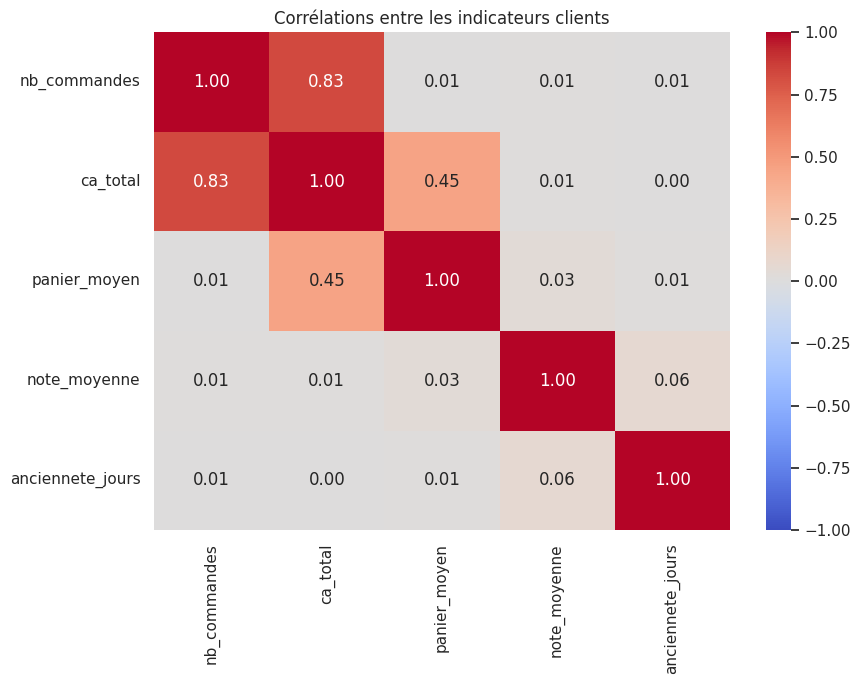

In [7]:
correlations = indicateurs_clients.corr(numeric_only=True)

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Corrélations entre les indicateurs clients")

plt.tight_layout()
plt.savefig(
    DOSSIER_FIGURES / "04_heatmap_indicateurs_clients.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()

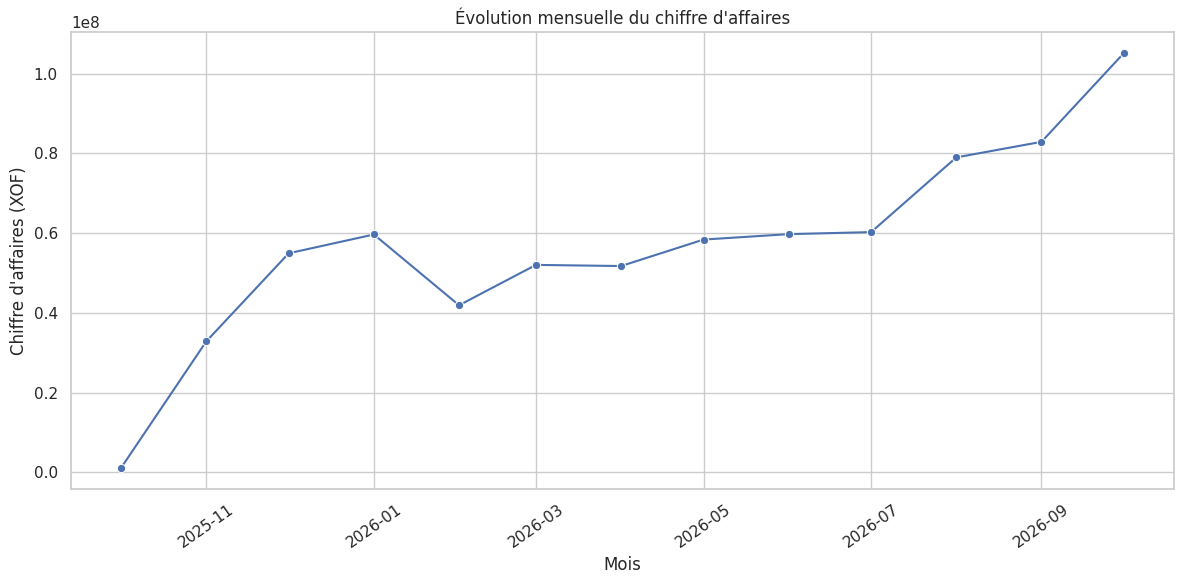

In [8]:
ventes_mensuelles = ventes.dropna(
    subset=["date_commande"]
).copy()

ventes_mensuelles["mois"] = (
    ventes_mensuelles["date_commande"].dt.to_period("M")
)

ca_mensuel = (
    ventes_mensuelles.groupby("mois", as_index=False)
    .agg(ca_total=("montant_xof", "sum"))
)

# Transformer les périodes en dates pour le graphique
ca_mensuel["mois"] = ca_mensuel["mois"].dt.to_timestamp()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=ca_mensuel,
    x="mois",
    y="ca_total",
    marker="o"
)

plt.title("Évolution mensuelle du chiffre d'affaires")
plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires (XOF)")
plt.xticks(rotation=35)

plt.tight_layout()
plt.savefig(
    DOSSIER_FIGURES / "05_evolution_mensuelle_ca.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()
plt.close()

In [9]:
fichiers_png = sorted(DOSSIER_FIGURES.glob("*.png"))

print(f"Nombre de graphiques PNG : {len(fichiers_png)}")

for fichier in fichiers_png:
    print("-", fichier.name)

Nombre de graphiques PNG : 5
- 01_distribution_montants.png
- 02_montants_par_ville.png
- 03_top10_produits_quantite.png
- 04_heatmap_indicateurs_clients.png
- 05_evolution_mensuelle_ca.png


In [10]:
fichiers_png = sorted(DOSSIER_FIGURES.glob("*.png"))

print(f"Nombre de graphiques générés : {len(fichiers_png)}")

for fichier in fichiers_png:
    print("✅", fichier.name)

Nombre de graphiques générés : 5
✅ 01_distribution_montants.png
✅ 02_montants_par_ville.png
✅ 03_top10_produits_quantite.png
✅ 04_heatmap_indicateurs_clients.png
✅ 05_evolution_mensuelle_ca.png
